<a href="https://colab.research.google.com/github/codeKrantz/AI-2010-FINAL-Project/blob/main/NCAA_Tournament_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NCAA March Madness AI 2010 Final Project
* Using data from Kaggle: https://www.kaggle.com/competitions/march-machine-learning-mania-2026/overview
* This notebook requires a KAGGLE_USERNAME and KAGGLE_KEY:


In [2]:
#@title Kaggle Username and API Key Validation
#this cell is used for crediential checking
from google.colab import userdata

u = userdata.get("KAGGLE_USERNAME")
k = userdata.get("KAGGLE_KEY")
print(repr(u))                       # should be your Kaggle username
print(len(k), k != k.strip())        # key length, and whether it has stray whitespace/newline

'conradkrantz'
39 True


In [3]:
#@title Kaggle Login
import kagglehub
kagglehub.login()

Kaggle credentials set.
Kaggle credentials successfully validated.


In [4]:
#@title Data Importing from Kaggle
import os
from google.colab import userdata

os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")

import kagglehub
import pandas as pd

path = kagglehub.competition_download("march-machine-learning-mania-2026")

# See what's there
files = sorted(os.listdir(path))
print(files)

# Load the men's files (they start with "M"); swap to "W" for women's
men = {
    f.replace(".csv", ""): pd.read_csv(os.path.join(path, f), encoding="latin-1")
    for f in files
    if f.startswith("M") and f.endswith(".csv")
}

for name, df in men.items():
    print(name, df.shape)

100%|██████████| 34.8M/34.8M [00:00<00:00, 104MB/s] 

Extracting files...


['Cities.csv', 'Conferences.csv', 'MConferenceTourneyGames.csv', 'MGameCities.csv', 'MMasseyOrdinals.csv', 'MNCAATourneyCompactResults.csv', 'MNCAATourneyDetailedResults.csv', 'MNCAATourneySeedRoundSlots.csv', 'MNCAATourneySeeds.csv', 'MNCAATourneySlots.csv', 'MRegularSeasonCompactResults.csv', 'MRegularSeasonDetailedResults.csv', 'MSeasons.csv', 'MSecondaryTourneyCompactResults.csv', 'MSecondaryTourneyTeams.csv', 'MTeamCoaches.csv', 'MTeamConferences.csv', 'MTeamSpellings.csv', 'MTeams.csv', 'SampleSubmissionStage1.csv', 'SampleSubmissionStage2.csv', 'WConferenceTourneyGames.csv', 'WGameCities.csv', 'WNCAATourneyCompactResults.csv', 'WNCAATourneyDetailedResults.csv', 'WNCAATourneySeeds.csv', 'WNCAATourneySlots.csv', 'WRegularSeasonCompactResults.csv', 'WRegularSeasonDetailedResults.csv', 'WSeasons.csv', 'WSecondaryTourneyCompactResults.csv', 'WSecondaryTourneyTeams.csv', 'WTeamConferences.csv', 'WTeamSpellings.csv', 'WTeams.csv']
MConferenceTourneyGames (7093, 5)
MGameCities (92438, 6

In [5]:
print(path)

/root/.cache/kagglehub/competitions/march-machine-learning-mania-2026


In [6]:
import pandas as pd
df = pd.read_csv(os.path.join(path, "MRegularSeasonDetailedResults.csv"))

In [7]:
df

,Season,DayNum,WTeamID,WScore,LTeamID,LScore,WLoc,NumOT,WFGM,WFGA,...,LFGA3,LFTM,LFTA,LOR,LDR,LAst,LTO,LStl,LBlk,LPF
0,2003,10,1104,68,1328,62,N,0,27,58,...,10,16,22,10,22,8,18,9,2,20
1,2003,10,1272,70,1393,63,N,0,26,62,...,24,9,20,20,25,7,12,8,6,16
2,2003,11,1266,73,1437,61,N,0,24,58,...,26,14,23,31,22,9,12,2,5,23
3,2003,11,1296,56,1457,50,N,0,18,38,...,22,8,15,17,20,9,19,4,3,23
4,2003,11,1400,77,1208,71,N,0,30,61,...,16,17,27,21,15,12,10,7,1,14
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
124524,2026,132,1335,88,1463,84,N,1,29,64,...,24,13,17,17,24,23,9,9,4,16
124525,2026,132,1345,80,1276,72,N,0,30,57,...,24,5,6,11,22,15,7,2,3,18
124526,2026,132,1378,70,1455,55,N,0,23,61,...,19,13,20,12,27,8,14,7,7,19
124527,2026,132,1433,70,1173,62,N,0,23,57,...,21,9,17,8,31,16,11,3,4,18


## Data Cleaning

In [8]:
#@title Load the data files used by the model
import os
import pandas as pd

# `path` is set by the Kaggle download cell above.
# Only the 4 files the models need are loaded here.
FILES = {
    "rs":      "MRegularSeasonDetailedResults.csv",  # features: regular-season box scores (2003+)
    "tourney": "MNCAATourneyDetailedResults.csv",    # labels: who won each NCAA tournament game
    "seeds":   "MNCAATourneySeeds.csv",              # seed-only baseline model
    "teams":   "MTeams.csv",                         # TeamID -> school name for readable output
}

missing = [f for f in FILES.values() if not os.path.exists(os.path.join(path, f))]
assert not missing, f"Missing files in {path}: {missing}"

def load(key):
    return pd.read_csv(os.path.join(path, FILES[key]), encoding="latin-1")

rs      = load("rs")
tourney = load("tourney")
seeds   = load("seeds")
teams   = load("teams")

# Summary of what was loaded
summary = pd.DataFrame([
    {
        "variable": name,
        "file": FILES[name],
        "rows": len(d),
        "columns": d.shape[1],
        "seasons": f"{d.Season.min()}-{d.Season.max()}" if "Season" in d else "-",
    }
    for name, d in {"rs": rs, "tourney": tourney, "seeds": seeds, "teams": teams}.items()
])
print(summary.to_string(index=False))

variable                              file   rows  columns   seasons
      rs MRegularSeasonDetailedResults.csv 124529       34 2003-2026
 tourney   MNCAATourneyDetailedResults.csv   1449       34 2003-2025
   seeds             MNCAATourneySeeds.csv   2694        3 1985-2026
   teams                        MTeams.csv    381        4         -


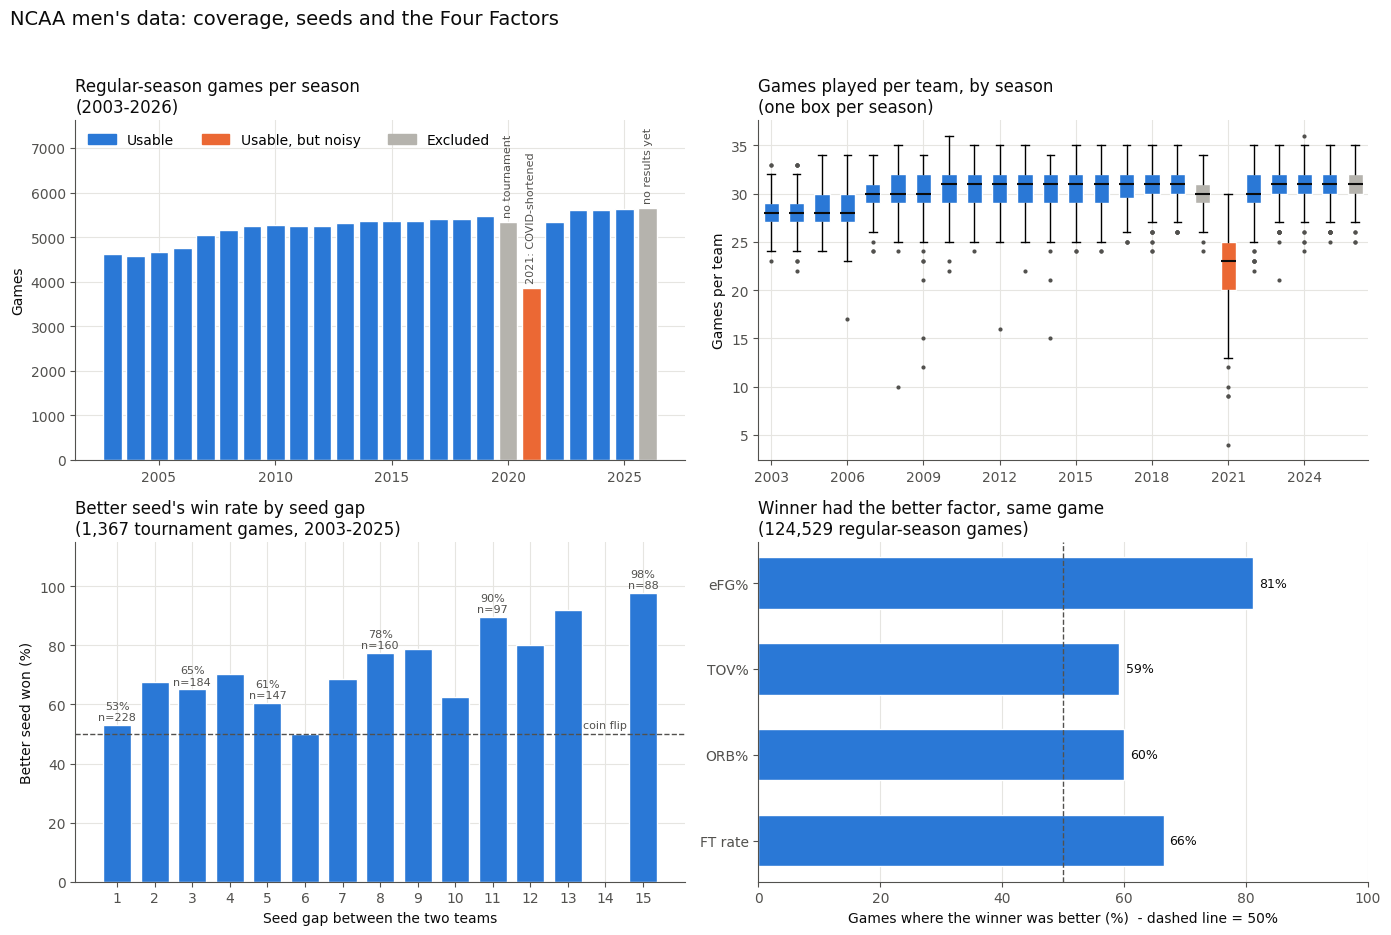

In [9]:
#@title Visualize the loaded data (exclude 2020 and acknowledge the reduced data from 2021 due to Covid)
import matplotlib.pyplot as plt

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#b5b3ad"
INK, MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10,
})

# Seasons that can't be used for training/testing
EXCLUDED = {2020: "no tournament", 2026: "no results yet"}

fig, axes = plt.subplots(2, 2, figsize=(14, 9.5))
fig.suptitle("NCAA men's data: coverage, seeds and the Four Factors", fontsize=14, x=0.01, ha="left", color=INK)

# 1. Regular-season games per season ------------------------------------
ax = axes[0, 0]
per_season = rs.groupby("Season").size()
colors = [GRAY if s in EXCLUDED else (ORANGE if s == 2021 else BLUE) for s in per_season.index]
ax.bar(per_season.index, per_season.values, color=colors, width=0.8, edgecolor="white", linewidth=1)
for s, why in EXCLUDED.items():
    ax.annotate(why, (s, per_season[s]), xytext=(0, 4), textcoords="offset points",
                ha="center", fontsize=8, color=MUTED, rotation=90, va="bottom")
ax.annotate("2021: COVID-shortened", (2021, per_season[2021]), xytext=(0, 4),
            textcoords="offset points", ha="center", fontsize=8, color=MUTED, rotation=90, va="bottom")
ax.set_title("Regular-season games per season\n(2003-2026)", loc="left", color=INK)
ax.set_ylabel("Games")
ax.set_ylim(0, per_season.max() * 1.35)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in (BLUE, ORANGE, GRAY)],
          labels=["Usable", "Usable, but noisy", "Excluded"], frameon=False, loc="upper left", ncol=3)

# 2. Games per team per season (shows how thin 2021 is) -----------------
ax = axes[0, 1]
long = pd.concat([rs[["Season", "WTeamID"]].rename(columns={"WTeamID": "TeamID"}),
                  rs[["Season", "LTeamID"]].rename(columns={"LTeamID": "TeamID"})])
gp = long.groupby(["Season", "TeamID"]).size().rename("games").reset_index()
seasons = sorted(gp.Season.unique())
bp = ax.boxplot([gp.loc[gp.Season == s, "games"] for s in seasons], positions=seasons,
                widths=0.6, patch_artist=True, showfliers=True,
                flierprops=dict(marker="o", markersize=3, markerfacecolor=MUTED, markeredgecolor="none"),
                medianprops=dict(color=INK, linewidth=1.5))
for patch, s in zip(bp["boxes"], seasons):
    patch.set_facecolor(GRAY if s in EXCLUDED else (ORANGE if s == 2021 else BLUE))
    patch.set_edgecolor("white")
ax.set_title("Games played per team, by season\n(one box per season)", loc="left", color=INK)
ax.set_ylabel("Games per team")
ax.set_xticks(seasons[::3], labels=[str(x) for x in seasons[::3]])

# 3. Higher seed's win rate by seed gap (seed-only baseline) ------------
ax = axes[1, 0]
s = seeds.assign(SeedNum=seeds.Seed.str[1:3].astype(int))[["Season", "TeamID", "SeedNum"]]
t = (tourney.merge(s.rename(columns={"TeamID": "WTeamID", "SeedNum": "WSeed"}), on=["Season", "WTeamID"])
            .merge(s.rename(columns={"TeamID": "LTeamID", "SeedNum": "LSeed"}), on=["Season", "LTeamID"]))
t["gap"] = (t.WSeed - t.LSeed).abs()
t = t[t.gap > 0]                                   # same-seed games (mostly First Four) have no favorite
t["fav_won"] = t.WSeed < t.LSeed
by_gap = t.groupby("gap").fav_won.agg(["mean", "size"])
ax.bar(by_gap.index, by_gap["mean"] * 100, color=BLUE, width=0.75, edgecolor="white", linewidth=1)
ax.axhline(50, color=MUTED, linewidth=1, linestyle="--")
ax.text(14, 51.5, "coin flip", fontsize=8, color=MUTED, ha="center", va="bottom")
for g, row in by_gap.iterrows():
    if g in (1, 3, 5, 8, 11, 15):
        ax.text(g, row["mean"] * 100 + 1.5, f"{row['mean']:.0%}\nn={int(row['size'])}",
                ha="center", fontsize=8, color=MUTED)
ax.set_title(f"Better seed's win rate by seed gap\n({len(t):,} tournament games, 2003-2025)", loc="left", color=INK)
ax.set_xlabel("Seed gap between the two teams")
ax.set_ylabel("Better seed won (%)")
ax.set_ylim(0, 115)
ax.set_xticks(range(1, 16))

# 4. How often the winner had the better Four Factor ---------------------
ax = axes[1, 1]
def factors(p, o):
    return pd.DataFrame({
        "eFG%":     (rs[p+"FGM"] + 0.5 * rs[p+"FGM3"]) / rs[p+"FGA"],
        "TOV%":     rs[p+"TO"] / (rs[p+"FGA"] + 0.44 * rs[p+"FTA"] + rs[p+"TO"]),
        "ORB%":     rs[p+"OR"] / (rs[p+"OR"] + rs[o+"DR"]),
        "FT rate":  rs[p+"FTA"] / rs[p+"FGA"],
    })
w, l = factors("W", "L"), factors("L", "W")
better = {
    "eFG%":    (w["eFG%"] > l["eFG%"]).mean(),
    "TOV%":    (w["TOV%"] < l["TOV%"]).mean(),     # fewer turnovers is better
    "ORB%":    (w["ORB%"] > l["ORB%"]).mean(),
    "FT rate": (w["FT rate"] > l["FT rate"]).mean(),
}
names, vals = list(better), [v * 100 for v in better.values()]
bars = ax.barh(names[::-1], vals[::-1], color=BLUE, height=0.6, edgecolor="white", linewidth=1)
ax.axvline(50, color=MUTED, linewidth=1, linestyle="--")
for b, v in zip(bars, vals[::-1]):
    ax.text(v + 1, b.get_y() + b.get_height() / 2, f"{v:.0f}%", va="center", fontsize=9, color=INK)
ax.set_xlim(0, 100)
ax.set_title(f"Winner had the better factor, same game\n({len(rs):,} regular-season games)",
             loc="left", color=INK)
ax.set_xlabel("Games where the winner was better (%)  - dashed line = 50%")
ax.grid(axis="y", visible=False)

fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

In [10]:
#@title Validate the loaded data
# Runs every check, prints a pass/fail table, then stops the notebook if a
# hard check failed. WARN rows are known quirks that the clean cell handles.
results = []

def check(file, name, bad_count, level="FAIL", detail=""):
    """bad_count = number of rows that break the rule (0 means it passes)."""
    status = "PASS" if bad_count == 0 else level
    results.append({"file": file, "check": name, "bad rows": int(bad_count),
                    "status": status, "detail": detail if bad_count else ""})

# ---------- Box-score checks (same rules for regular season and tournament) ----------
for label, g in [("rs", rs), ("tourney", tourney)]:
    check(label, "No missing values", g.isna().sum().sum())
    check(label, "No duplicate games",
          g.duplicated(["Season", "DayNum", "WTeamID", "LTeamID"]).sum())
    check(label, "No negative stats", (g.select_dtypes("number") < 0).sum().sum())
    check(label, "Winner outscored loser", (g.WScore <= g.LScore).sum())
    check(label, "A team never plays itself", (g.WTeamID == g.LTeamID).sum())
    check(label, "WLoc is H, A or N", (~g.WLoc.isin(["H", "A", "N"])).sum())

    for p, o in [("W", "L"), ("L", "W")]:
        side = "winner" if p == "W" else "loser"
        check(label, f"{side}: makes <= attempts (FG, 3PT, FT)",
              ((g[p+"FGM"] > g[p+"FGA"]) | (g[p+"FGM3"] > g[p+"FGA3"]) | (g[p+"FTM"] > g[p+"FTA"])).sum())
        check(label, f"{side}: 3PT makes/attempts <= all FG makes/attempts",
              ((g[p+"FGM3"] > g[p+"FGM"]) | (g[p+"FGA3"] > g[p+"FGA"])).sum())
        check(label, f"{side}: score = 2*FGM + FGM3 + FTM",
              (2 * g[p+"FGM"] + g[p+"FGM3"] + g[p+"FTM"] != g[p+"Score"]).sum())
        # Denominators used by the Four Factors must never be zero
        check(label, f"{side}: Four Factors denominators > 0",
              ((g[p+"FGA"] == 0) | (g[p+"OR"] + g[o+"DR"] == 0)).sum())

    ids = pd.concat([g.WTeamID, g.LTeamID])
    check(label, "Every TeamID exists in MTeams", (~ids.isin(teams.TeamID)).sum())

    # A team should play at most one game per day
    long = pd.concat([g[["Season", "DayNum", "WTeamID"]].rename(columns={"WTeamID": "TeamID"}),
                      g[["Season", "DayNum", "LTeamID"]].rename(columns={"LTeamID": "TeamID"})])
    dup_day = long[long.duplicated(keep=False)]
    check(label, "Team plays at most once per day", dup_day.duplicated().sum(), level="WARN",
          detail=", ".join(f"{r.Season} day {r.DayNum} team {r.TeamID}"
                           for r in dup_day.drop_duplicates().itertuples()))

# ---------- File-specific checks ----------
check("rs", "Regular season ends by DayNum 132", (rs.DayNum > 132).sum())
check("tourney", "Tournament games start at DayNum 134", (tourney.DayNum < 134).sum())
check("tourney", "All tournament games on a neutral court", (tourney.WLoc != "N").sum())

missing_seasons = sorted(set(range(2003, 2026)) - set(tourney.Season))
check("tourney", "A tournament every season 2003-2025", len(missing_seasons), level="WARN",
      detail=f"missing: {missing_seasons}")

check("seeds", "Seed format is region + 2 digits (+ a/b)",
      (~seeds.Seed.str.match(r"^[WXYZ]\d{2}[ab]?$")).sum())
check("seeds", "Each team seeded at most once per season",
      seeds.duplicated(["Season", "TeamID"]).sum())
check("seeds", "Every seeded TeamID exists in MTeams", (~seeds.TeamID.isin(teams.TeamID)).sum())
field = seeds.groupby("Season").size()
check("seeds", "Field size is 64, 65 or 68 teams", (~field.isin([64, 65, 68])).sum())

check("teams", "TeamIDs are unique", teams.TeamID.duplicated().sum())
check("teams", "No missing team names", teams.TeamName.isna().sum())

# ---------- Cross-file checks ----------
seed_keys = set(zip(seeds.Season, seeds.TeamID))
t_keys = list(zip(tourney.Season, tourney.WTeamID)) + list(zip(tourney.Season, tourney.LTeamID))
check("tourney+seeds", "Every tournament team has a seed",
      sum(k not in seed_keys for k in t_keys))

games_per_team = (pd.concat([rs[["Season", "WTeamID"]].rename(columns={"WTeamID": "TeamID"}),
                             rs[["Season", "LTeamID"]].rename(columns={"LTeamID": "TeamID"})])
                    .groupby(["Season", "TeamID"]).size())
seeded = seeds[seeds.Season >= 2003].set_index(["Season", "TeamID"]).index
n_games = games_per_team.reindex(seeded)
check("seeds+rs", "Every seeded team has regular-season games", n_games.isna().sum())
thin = n_games[n_games < 20]
check("seeds+rs", "Seeded teams played 20+ games", len(thin), level="WARN",
      detail=", ".join(f"{s} team {t}: {int(n)}" for (s, t), n in thin.items()))

# ---------- Report ----------
report = pd.DataFrame(results)
pd.set_option("display.max_colwidth", 80)
print(report.to_string(index=False))

counts = report.status.value_counts()
print(f"\n{counts.get('PASS', 0)} passed, {counts.get('WARN', 0)} warnings, {counts.get('FAIL', 0)} failed")
assert counts.get("FAIL", 0) == 0, "Data validation failed - see the FAIL rows above"
print("All hard checks passed. The data is safe to clean and model.")

         file                                               check  bad rows status                                                                         detail
           rs                                   No missing values         0   PASS                                                                               
           rs                                  No duplicate games         0   PASS                                                                               
           rs                                   No negative stats         0   PASS                                                                               
           rs                              Winner outscored loser         0   PASS                                                                               
           rs                           A team never plays itself         0   PASS                                                                               
           rs               

In [11]:
#@title Clean and filter the data
# Builds cleaned copies (rs_clean, tourney_clean, seeds_clean) and leaves the raw
# tables untouched, so this cell can be re-run safely.
log = []   # change log: one row per cleaning step

def record(step, table, before, after, reason):
    log.append({"step": step, "table": table, "rows before": before,
                "rows after": after, "rows removed": before - after, "reason": reason})

# ---- Step 1: keep only seasons that have both features and tournament labels ----
# 2003 = first season with box scores. 2020 = no tournament (COVID). 2026 = no results yet.
EXCLUDED_SEASONS = {2020: "no tournament (COVID)", 2026: "tournament results not available"}
SEASONS = [s for s in range(2003, 2026) if s not in EXCLUDED_SEASONS]

rs_clean = rs[rs.Season.isin(SEASONS)].copy()
record(1, "rs", len(rs), len(rs_clean), "drop 2020 and 2026 (no tournament labels)")

tourney_clean = tourney[tourney.Season.isin(SEASONS)].copy()
record(1, "tourney", len(tourney), len(tourney_clean), "drop 2020 and 2026 (none present)")

seeds_clean = seeds[seeds.Season.isin(SEASONS)].copy()
record(1, "seeds", len(seeds), len(seeds_clean), "keep 2003-2025 without 2020")

# ---- Step 2: parse seed strings into usable columns ----
# "X11a" -> Region "X", SeedNum 11, PlayIn True
seeds_clean["Region"]  = seeds_clean.Seed.str[0]
seeds_clean["SeedNum"] = seeds_clean.Seed.str[1:3].astype(int)
seeds_clean["PlayIn"]  = seeds_clean.Seed.str.len() == 4
record(2, "seeds", len(seeds_clean), len(seeds_clean), "added Region, SeedNum, PlayIn columns")

# ---- Step 3: drop First Four / opening-round games ----
# Identified by seed, not date: both teams share the same play-in seed (e.g. X11a vs X11b).
# Date alone misses 2021, when the First Four was played on day 136.
seed_lookup = seeds_clean.set_index(["Season", "TeamID"]).Seed

def seed_of(df, team_col):
    keys = pd.MultiIndex.from_frame(df[["Season", team_col]])
    return pd.Series(seed_lookup.reindex(keys).values, index=df.index)

w_seed, l_seed = seed_of(tourney_clean, "WTeamID"), seed_of(tourney_clean, "LTeamID")
is_first_four = (w_seed.str.len() == 4) & (w_seed.str[:3] == l_seed.str[:3])

before = len(tourney_clean)
first_four_games = tourney_clean[is_first_four]
tourney_clean = tourney_clean[~is_first_four].copy()
record(3, "tourney", before, len(tourney_clean),
       "drop First Four (same seed on both sides, so the seed model can't pick a favorite)")

# ---- Step 4: flag the COVID-shortened 2021 season (kept, not removed) ----
rs_clean["COVID2021"] = rs_clean.Season == 2021
tourney_clean["COVID2021"] = tourney_clean.Season == 2021
record(4, "rs + tourney", len(tourney_clean), len(tourney_clean),
       f"flagged 2021 ({rs_clean.COVID2021.sum():,} rs games, {tourney_clean.COVID2021.sum()} tourney games)")

# ---- Change log ----
change_log = pd.DataFrame(log)
print("CHANGE LOG")
print(change_log.to_string(index=False))

# ---- Post-cleaning checks ----
assert not rs_clean.Season.isin(EXCLUDED_SEASONS).any()
assert not tourney_clean.Season.isin(EXCLUDED_SEASONS).any()
assert len(first_four_games) == (seeds_clean.PlayIn.sum() // 2), "First Four count doesn't match play-in seeds"
assert seed_of(tourney_clean, "WTeamID").notna().all() and seed_of(tourney_clean, "LTeamID").notna().all()

games_per_season = tourney_clean.groupby("Season").size()
print(f"\nSeasons kept: {len(SEASONS)} ({SEASONS[0]}-{SEASONS[-1]}, no 2020)")
print(f"First Four games removed: {len(first_four_games)}")
print(f"Tournament games for modeling: {len(tourney_clean):,}")
print(f"Regular-season games for features: {len(rs_clean):,}")
odd = games_per_season[games_per_season != 63]
if len(odd):
    print("Seasons without 63 games:", odd.to_dict(),
          "(2021: VCU-Oregon was declared a no-contest due to COVID)")

CHANGE LOG
 step        table  rows before  rows after  rows removed                                                                             reason
    1           rs       124529      113554         10975                                          drop 2020 and 2026 (no tournament labels)
    1      tourney         1449        1449             0                                                  drop 2020 and 2026 (none present)
    1        seeds         2694        1472          1222                                                        keep 2003-2025 without 2020
    2        seeds         1472        1472             0                                              added Region, SeedNum, PlayIn columns
    3      tourney         1449        1385            64 drop First Four (same seed on both sides, so the seed model can't pick a favorite)
    4 rs + tourney         1385        1385             0                                    flagged 2021 (3,855 rs games, 62 tourney games)

S

## Feature engineering

**Goal:** turn each regular season into one profile per team, then describe each tournament matchup as the *difference* between the two teams' profiles. Only regular-season games (DayNum ≤ 132) are used to build features, so nothing from the tournament leaks into the inputs.

### Step 1: One row per team per game
The raw data stores each game as **winner vs. loser**. Averaging only winner columns would describe *winning*, not the team. So every game is split into two rows, one from each team's point of view:

| Column group | Meaning |
|---|---|
| `Team…` | the team's own box score (its offense) |
| `Opp…` | the opponent's box score in that game (what the team's defense allowed) |

### Step 2: Season totals → Four Factors
For each team and season, the box-score stats are **summed first, then turned into rates**. This weights every possession equally, so a few blowouts or slow games can't skew the result the way averaging per-game percentages would.

| Factor | Offense (team's own) | Defense (opponent's, allowed by the team) |
|---|---|---|
| **Shooting**: eFG% | (FGM + 0.5·FGM3) / FGA | opponent eFG% allowed |
| **Turnovers**: TOV% | TO / (FGA + 0.44·FTA + TO) | opponent TOV% forced |
| **Rebounding**: ORB% | OR / (OR + opponent DR) | opponent ORB% allowed |
| **Free throws**: FT rate | FTA / FGA | opponent FT rate allowed |

That gives **8 numbers per team-season**: 4 offense and 4 defense. Defense uses the *same formulas* applied to the opponent's stats, so the two sides are directly comparable.

Direction matters. Higher is better for offensive eFG%, ORB% and FT rate, but lower is better for offensive TOV%. On defense it flips: lower allowed eFG% is better, and higher forced TOV% is better. Logistic regression learns these signs on its own, so no values are flipped by hand.

### Step 3: Season normalization (z-scores)
College basketball changes over time (more 3-pointers, fewer free throws), so a 52% eFG% means something different in 2005 than in 2025. Each factor is converted to a **z-score within its season**:

> z = (team value − season average) / season standard deviation

A z of +1.0 means one standard deviation better than that season's average, which makes all 22 seasons comparable.

### Step 4: Matchup features (Team A − Team B)
Each tournament game becomes one row:
- **Team A** = the lower TeamID, **Team B** = the higher TeamID (the same convention Kaggle uses).
- **Label** = 1 if Team A won, 0 if Team B won. Ordering by TeamID instead of winner/loser keeps the labels balanced, close to 50/50.
- **Features** = Team A's value − Team B's value for each input.

### Step 5: Three feature sets, one per model

| Model | Features | Count |
|---|---|---|
| **Seed-only** (baseline) | seed difference (A − B) | 1 |
| **Offense-only** | eFG%, TOV%, ORB%, FT rate differences (offense) | 4 |
| **Defense-only** | eFG%, TOV%, ORB%, FT rate differences (allowed) | 4 |

Offense and defense get the **same number of features built the same way**, so neither model has an advantage from having more inputs. The comparison is about which side's stats predict tournament winners better.

In [12]:
#@title Build features: Four Factors (offense & defense), season z-scores, matchups
import numpy as np
STATS = ["Score", "FGM", "FGA", "FGM3", "FGA3", "FTM", "FTA", "OR", "DR", "Ast", "TO", "Stl", "Blk", "PF"]

# ---- Step 1: one row per team per game (team's own stats + opponent's stats) ----
def team_view(df, me, opp):
    out = df[["Season", "DayNum"]].copy()
    out["TeamID"] = df[me + "TeamID"]
    out["OppID"]  = df[opp + "TeamID"]
    for s in STATS:
        out["Team" + s] = df[me + s]
        out["Opp" + s]  = df[opp + s]
    return out

team_games = pd.concat([team_view(rs_clean, "W", "L"), team_view(rs_clean, "L", "W")],
                       ignore_index=True)
assert len(team_games) == 2 * len(rs_clean)

# ---- Step 2: season totals -> Four Factors ----
SUM_COLS = [side + s for side in ("Team", "Opp") for s in STATS]
totals = team_games.groupby(["Season", "TeamID"])[SUM_COLS].sum()
totals["Games"] = team_games.groupby(["Season", "TeamID"]).size()

def four_factors(t, me, opp):
    """Four Factors for side `me` ('Team' = offense, 'Opp' = what the defense allowed)."""
    return pd.DataFrame({
        "eFG": (t[me+"FGM"] + 0.5 * t[me+"FGM3"]) / t[me+"FGA"],
        "TOV": t[me+"TO"] / (t[me+"FGA"] + 0.44 * t[me+"FTA"] + t[me+"TO"]),
        "ORB": t[me+"OR"] / (t[me+"OR"] + t[opp+"DR"]),
        "FTR": t[me+"FTA"] / t[me+"FGA"],
    }, index=t.index)

off = four_factors(totals, "Team", "Opp").add_prefix("Off_")
dfn = four_factors(totals, "Opp", "Team").add_prefix("Def_")
team_feats = pd.concat([off, dfn, totals[["Games"]]], axis=1)
FACTOR_COLS = list(off.columns) + list(dfn.columns)

# ---- Step 3: z-score each factor within its season (all D-I teams) ----
season_mean = team_feats.groupby(level="Season")[FACTOR_COLS].transform("mean")
season_std  = team_feats.groupby(level="Season")[FACTOR_COLS].transform("std")
team_z = (team_feats[FACTOR_COLS] - season_mean) / season_std
team_z = team_z.reset_index()

# ---- Step 4: tournament matchups, Team A = lower TeamID ----
m = tourney_clean[["Season", "DayNum", "WTeamID", "LTeamID", "COVID2021"]].copy()
m["TeamA"] = m[["WTeamID", "LTeamID"]].min(axis=1)
m["TeamB"] = m[["WTeamID", "LTeamID"]].max(axis=1)
m["Label"] = (m.WTeamID == m.TeamA).astype(int)

seed_num = seeds_clean[["Season", "TeamID", "SeedNum"]]
for side in ("A", "B"):
    m = (m.merge(team_z.rename(columns={"TeamID": "Team" + side, **{c: f"{c}_{side}" for c in FACTOR_COLS}}),
                 on=["Season", "Team" + side], how="left")
          .merge(seed_num.rename(columns={"TeamID": "Team" + side, "SeedNum": "Seed_" + side}),
                 on=["Season", "Team" + side], how="left"))

# Differences (A - B)
m["SeedDiff"] = m.Seed_A - m.Seed_B
for c in FACTOR_COLS:
    m[c + "_diff"] = m[c + "_A"] - m[c + "_B"]

SEED_FEATURES = ["SeedDiff"]
OFF_FEATURES  = [c + "_diff" for c in off.columns]
DEF_FEATURES  = [c + "_diff" for c in dfn.columns]

matchups = m[["Season", "DayNum", "TeamA", "TeamB", "Label", "COVID2021",
              "Seed_A", "Seed_B"] + SEED_FEATURES + OFF_FEATURES + DEF_FEATURES]

# ---- Checks ----
assert len(matchups) == len(tourney_clean), "lost or duplicated games while merging"
assert matchups[SEED_FEATURES + OFF_FEATURES + DEF_FEATURES].notna().all().all(), "missing features"
assert team_feats[FACTOR_COLS].notna().all().all() and np.isfinite(team_feats[FACTOR_COLS]).all().all()
z_check = team_z.groupby("Season")[FACTOR_COLS].agg(["mean", "std"])
assert z_check.xs("mean", axis=1, level=1).abs().max().max() < 1e-9
assert (z_check.xs("std", axis=1, level=1) - 1).abs().max().max() < 1e-9

# ---- Summary ----
print(f"Team-game rows: {len(team_games):,}  |  team-seasons: {len(team_feats):,}  |  matchups: {len(matchups):,}")
print(f"Label balance (Team A won): {matchups.Label.mean():.1%}")
print("\nRaw Four Factors, average across all teams (sanity check):")
print(team_feats[FACTOR_COLS].groupby(level="Season").mean().loc[[2003, 2013, 2025]].round(3).to_string())

names = teams.set_index("TeamID").TeamName
ex = matchups.iloc[-1]
print(f"\nExample row: {ex.Season} {names[ex.TeamA]} ({int(ex.Seed_A)}) vs "
      f"{names[ex.TeamB]} ({int(ex.Seed_B)}), Label={int(ex.Label)}")
print(matchups.iloc[[-1]][SEED_FEATURES + OFF_FEATURES + DEF_FEATURES].round(2).to_string(index=False))

Team-game rows: 227,108  |  team-seasons: 7,628  |  matchups: 1,385
Label balance (Team A won): 50.4%

Raw Four Factors, average across all teams (sanity check):
        Off_eFG  Off_TOV  Off_ORB  Off_FTR  Def_eFG  Def_TOV  Def_ORB  Def_FTR
Season                                                                        
2003      0.494    0.187    0.335    0.369    0.495    0.186    0.337    0.370
2013      0.486    0.174    0.317    0.360    0.487    0.173    0.318    0.362
2025      0.508    0.145    0.277    0.331    0.509    0.144    0.278    0.332

Example row: 2025 Florida (1) vs Houston (1), Label=1
 SeedDiff  Off_eFG_diff  Off_TOV_diff  Off_ORB_diff  Off_FTR_diff  Def_eFG_diff  Def_TOV_diff  Def_ORB_diff  Def_FTR_diff
        0          0.77          0.38          0.27          0.95          0.16         -1.94          0.43         -0.21


### What the feature visuals show

**Left chart: who wins when one team has the edge?**
Each dot is the share of tournament games won by the team that was better in one factor during the regular season. 50% is a coin flip; the dotted line is the seed baseline (71%).
- **Shooting** is the strongest single factor on both sides: better shooting defense won 60% and better shooting offense won 57%.
- **Turnovers and rebounding** mattered on offense (58%, 60%) but were close to a coin flip on defense (52%, 51%).
- **Free throws** flipped: getting to the line more on offense won only 47%, while limiting opponents' free throws won 54%.
- No single factor beats seeds. The models will test whether all four together can.

**Right chart: how related are the features?**
Each cell is the correlation between two features across 7,628 team-seasons. All values are weak to moderate (largest = 0.39), so the features don't repeat each other and logistic regression can separate their effects. Colors show statistical direction, not good vs. bad.

*These are one-factor-at-a-time previews. Small gaps can be noise; the models with leave-one-season-out testing give the real answer.*

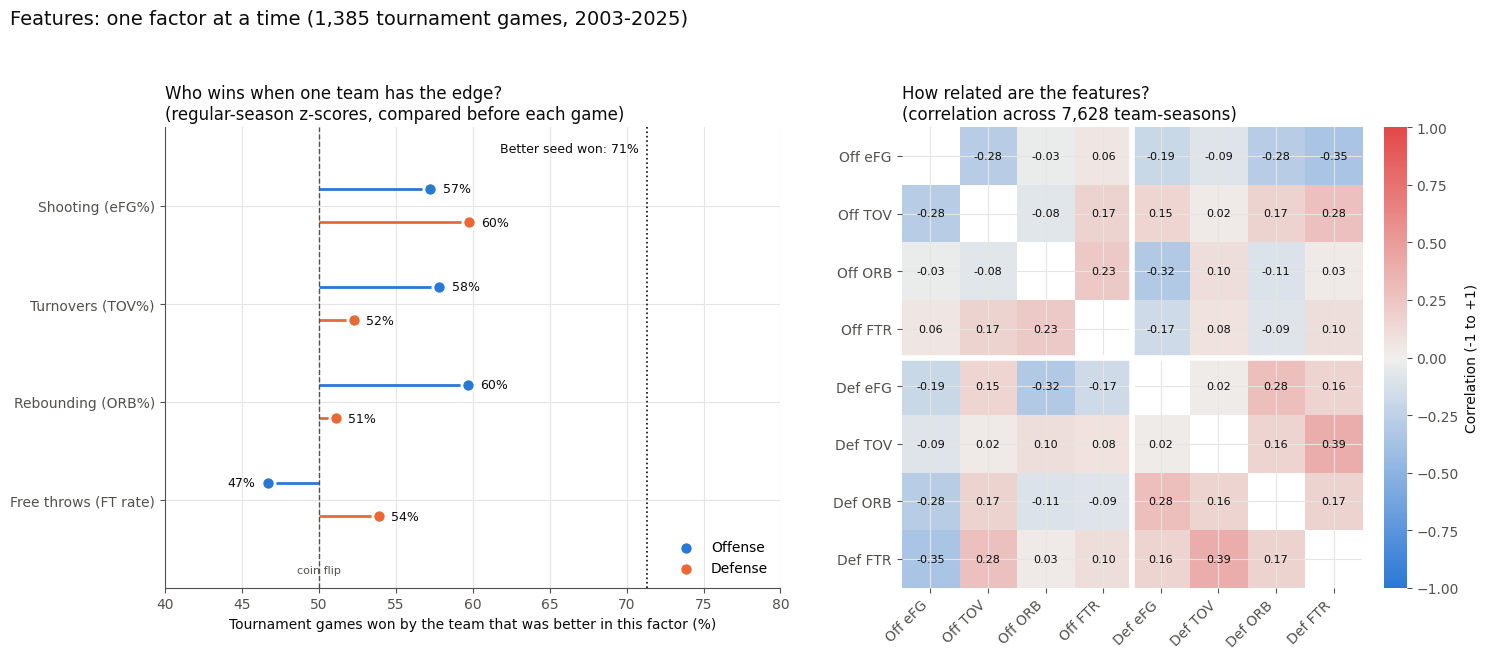

Team with the better factor won:
                       Offense %  Defense %
Shooting (eFG%)             57.3       59.8
Turnovers (TOV%)            57.8       52.3
Rebounding (ORB%)           59.7       51.1
Free throws (FT rate)       46.7       53.9
Better seed won: 71.3% (1,367 games with different seeds)


In [13]:
#@title Visualize the features
import numpy as np
import matplotlib.pyplot as plt

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#b5b3ad"
INK, MUTED = "#0b0b0b", "#52514e"
DIVERGING = plt.matplotlib.colors.LinearSegmentedColormap.from_list(
    "blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"])

FACTOR_NAMES = {"eFG": "Shooting (eFG%)", "TOV": "Turnovers (TOV%)",
                "ORB": "Rebounding (ORB%)", "FTR": "Free throws (FT rate)"}
# +1 if a HIGHER value is better for the team, -1 if LOWER is better
BETTER_IF_HIGHER = {"Off_eFG": 1, "Off_TOV": -1, "Off_ORB": 1, "Off_FTR": 1,
                    "Def_eFG": -1, "Def_TOV": 1, "Def_ORB": -1, "Def_FTR": -1}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={"width_ratios": [1.15, 1]})
fig.suptitle(f"Features: one factor at a time ({len(matchups):,} tournament games, 2003-2025)",
             fontsize=14, x=0.01, ha="left", color=INK)

# ---- 1. How often the team that was better in each factor won ----
def better_team_won(col):
    edge = matchups[col + "_diff"] * BETTER_IF_HIGHER[col]   # >0 means Team A was better
    edge = edge[edge != 0]
    a_won = matchups.loc[edge.index, "Label"] == 1
    return ((edge > 0) == a_won).mean() * 100

factors = list(FACTOR_NAMES)
off_rates = [better_team_won("Off_" + f) for f in factors]
def_rates = [better_team_won("Def_" + f) for f in factors]
y = np.arange(len(factors))[::-1]
offset = 0.17
# Dot plot measured from the 50% coin-flip line (bars would need to start at 0)
for rates, color, dy, name in ((off_rates, BLUE, offset, "Offense"), (def_rates, ORANGE, -offset, "Defense")):
    ax1.hlines(y + dy, 50, rates, color=color, linewidth=2)
    ax1.scatter(rates, y + dy, s=90, color=color, zorder=3, edgecolor="white", linewidth=2, label=name)
    for yy, r in zip(y + dy, rates):
        ax1.text(r + (0.8 if r >= 50 else -0.8), yy, f"{r:.0f}%", va="center",
                 ha="left" if r >= 50 else "right", fontsize=9, color=INK)

seeded = matchups[matchups.SeedDiff != 0]
seed_rate = ((seeded.SeedDiff < 0) == (seeded.Label == 1)).mean() * 100
ax1.axvline(seed_rate, color=INK, linewidth=1.2, linestyle=":")
ax1.text(seed_rate - 0.5, len(factors) - 0.45, f"Better seed won: {seed_rate:.0f}%",
         fontsize=9, color=INK, ha="right")
ax1.axvline(50, color=MUTED, linewidth=1, linestyle="--")
ax1.text(50, -0.75, "coin flip", fontsize=8, color=MUTED, ha="center")

ax1.set_yticks(y, [FACTOR_NAMES[f] for f in factors])
ax1.set_xlim(40, 80)
ax1.set_ylim(-0.9, len(factors) - 0.2)
ax1.set_xlabel("Tournament games won by the team that was better in this factor (%)")
ax1.set_title("Who wins when one team has the edge?\n(regular-season z-scores, compared before each game)",
              loc="left", color=INK)
ax1.legend(frameon=False, loc="lower right")
for side in ("top", "right"):
    ax1.spines[side].set_visible(False)
ax1.grid(axis="x", color="#e6e5e1")
ax1.set_axisbelow(True)

# ---- 2. Correlation between the 8 features (team-season level) ----
labels = [c.replace("Off_", "Off ").replace("Def_", "Def ") for c in FACTOR_COLS]
corr = team_z[FACTOR_COLS].corr()
shown = corr.values.copy()
np.fill_diagonal(shown, np.nan)                     # a feature vs itself is always 1.00
DIVERGING.set_bad("white")
im = ax2.imshow(shown, cmap=DIVERGING, vmin=-1, vmax=1)
ax2.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
ax2.set_yticks(range(len(labels)), labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        if i == j:
            continue
        v = corr.values[i, j]
        ax2.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                 color="white" if abs(v) > 0.6 else INK)
ax2.axhline(3.5, color="white", linewidth=4)
ax2.axvline(3.5, color="white", linewidth=4)
ax2.set_title(f"How related are the features?\n(correlation across {len(team_z):,} team-seasons)",
              loc="left", color=INK)
for spine in ax2.spines.values():
    spine.set_visible(False)
cb = fig.colorbar(im, ax=ax2, fraction=0.046, pad=0.04)
cb.set_label("Correlation (-1 to +1)")
cb.outline.set_visible(False)

fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

print("Team with the better factor won:")
print(pd.DataFrame({"Offense %": off_rates, "Defense %": def_rates},
                   index=[FACTOR_NAMES[f] for f in factors]).round(1).to_string())
print(f"Better seed won: {seed_rate:.1f}% ({len(seeded):,} games with different seeds)")

## Modeling: seed vs. offense vs. defense

**Question:** whose regular-season stats better predict NCAA tournament winners, a team's offense or its defense?

### Three models, same method
All three are **logistic regression**: they turn the matchup features into a probability that Team A wins. Only the inputs change:

| Model | Inputs (Team A − Team B) | Role |
|---|---|---|
| **Seed-only** | seed difference (1 feature) | Baseline: what the selection committee already knows |
| **Offense-only** | eFG%, TOV%, ORB%, FT rate (4 features) | Tests offense |
| **Defense-only** | eFG%, TOV%, ORB%, FT rate allowed (4 features) | Tests defense |

Offense and defense get the same number of features, built the same way, so neither has an advantage from more inputs. Features are standardized inside a pipeline, so each model learns the scaling only from its training data.

### Testing: leave-one-season-out
There are 22 seasons (2003–2025, without 2020). For each season:
1. **Train** on the other 21 seasons.
2. **Predict** every tournament game in the held-out season.

Each game is predicted by a model that never saw that season, just like predicting a new tournament. This repeats 22 times, so every one of the 1,385 games gets one out-of-sample prediction from each model.

### How the models are scored
| Metric | What it measures | Better is |
|---|---|---|
| **Accuracy** | % of games where the model picked the winner | Higher |
| **Log loss** | Quality of the probabilities; confident wrong picks are punished heavily (the Kaggle metric) | Lower |
| **Brier score** | Average squared gap between the probability and the result (0 or 1) | Lower |

A model that always predicts 50% scores 50% accuracy, a log loss of 0.693 and a Brier score of 0.25. Any useful model must beat these numbers.

### How the winner is decided
The main metric is the **Brier score**. For each season, the gap is calculated as **Defense Brier − Offense Brier**, so a positive gap means offense predicted better.

A difference counts as **real only if both** are true:
1. The **season-level bootstrap 95% interval** for the pooled gap excludes zero. Whole seasons are resampled with replacement 10,000 times, because games within the same tournament aren't independent.
2. The **same side has the better Brier score in most of the 22 seasons**.

If either condition fails, the result is reported as a **tie**.

In [18]:
#@title Train, test and compare the three models (plan: Brier + season bootstrap)
# Model choice: logistic regression.
# It beat random forest, gradient boosting and a small neural net on log loss
# for all three feature sets in a leave-one-season-out comparison. With ~1,400 games
# and 1-4 features, more complex models overfit the training seasons. Logistic
# regression also gives one readable coefficient per factor.
import numpy as np
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss, brier_score_loss

FEATURE_SETS = {"Seed": SEED_FEATURES, "Offense": OFF_FEATURES, "Defense": DEF_FEATURES}
N_BOOT, RANDOM_SEED = 10_000, 2010

def make_model():
    # Scaling lives inside the pipeline, so it is learned from training seasons only
    return make_pipeline(StandardScaler(), LogisticRegression())

# ---------- 1. Leave-one-season-out: hold out one tournament, train on the rest ----------
preds = matchups[["Season", "DayNum", "TeamA", "TeamB", "Label", "COVID2021"]].copy()
for season in sorted(matchups.Season.unique()):
    test = matchups.Season == season
    for name, cols in FEATURE_SETS.items():
        model = make_model().fit(matchups.loc[~test, cols], matchups.loc[~test, "Label"])
        preds.loc[test, "p_" + name] = model.predict_proba(matchups.loc[test, cols])[:, 1]

assert preds.filter(like="p_").notna().all().all(), "some games were never predicted"
SEASONS_TESTED = preds.Season.nunique()

# Per-game Brier score = (predicted probability - actual result)^2
for name in FEATURE_SETS:
    preds["brier_" + name] = (preds["p_" + name] - preds.Label) ** 2

# ---------- 2. Brier score for each season ----------
season_brier = preds.groupby("Season")[[f"brier_{n}" for n in FEATURE_SETS]].mean()
season_brier.columns = list(FEATURE_SETS)
season_brier["Gap (Def - Off)"] = season_brier.Defense - season_brier.Offense
season_brier["Better side"] = np.where(season_brier["Gap (Def - Off)"] > 0, "Offense",
                              np.where(season_brier["Gap (Def - Off)"] < 0, "Defense", "Tie"))
season_brier.insert(0, "Games", preds.groupby("Season").size())

print("BRIER SCORE BY HELD-OUT SEASON (lower is better)")
print(season_brier.round(4).to_string())

# ---------- 3. Pooled across seasons (main metric = Brier; others are supporting) ----------
def pooled(name):
    y, p = preds.Label, preds["p_" + name]
    return {"Brier": brier_score_loss(y, p), "Log loss": log_loss(y, p),
            "Accuracy": accuracy_score(y, p > 0.5)}

overall = pd.DataFrame({name: pooled(name) for name in FEATURE_SETS}).T
coin = np.full(len(preds), 0.5)
overall.loc["Coin flip (always 50%)"] = [brier_score_loss(preds.Label, coin),
                                         log_loss(preds.Label, coin), np.nan]
print(f"\nPOOLED ACROSS {SEASONS_TESTED} SEASONS ({len(preds):,} games)")
print(overall.round(4).to_string(na_rep="-"))

# ---------- 4. Season-level bootstrap 95% interval for the offense-vs-defense gap ----------
# Whole seasons are resampled (not single games), because games in the same
# tournament share the same trained model and aren't independent.
game_gap = preds.brier_Defense - preds.brier_Offense            # > 0 means offense was better
per_season = game_gap.groupby(preds.Season).agg(["sum", "size"])
observed_gap = per_season["sum"].sum() / per_season["size"].sum()

rng = np.random.default_rng(RANDOM_SEED)
picks = rng.integers(0, SEASONS_TESTED, size=(N_BOOT, SEASONS_TESTED))
boot_gaps = per_season["sum"].values[picks].sum(axis=1) / per_season["size"].values[picks].sum(axis=1)
ci_low, ci_high = np.percentile(boot_gaps, [2.5, 97.5])

# ---------- 5. Decision rule ----------
off_wins = (season_brier["Better side"] == "Offense").sum()
def_wins = (season_brier["Better side"] == "Defense").sum()
interval_excludes_zero = ci_low > 0 or ci_high < 0
leader = "Offense" if observed_gap > 0 else "Defense"
leader_wins = off_wins if leader == "Offense" else def_wins
majority = leader_wins > SEASONS_TESTED / 2

print("\nOFFENSE vs DEFENSE")
print(f"  Pooled Brier gap (Def - Off): {observed_gap:+.4f}   (positive = offense predicted better)")
print(f"  Season bootstrap 95% interval: [{ci_low:+.4f}, {ci_high:+.4f}]   ({N_BOOT:,} resamples)")
print(f"  Seasons won: Offense {off_wins}, Defense {def_wins} (of {SEASONS_TESTED})")
print(f"  Condition 1 - interval excludes zero:          {'PASS' if interval_excludes_zero else 'FAIL'}")
print(f"  Condition 2 - {leader} wins most seasons:      {'PASS' if majority else 'FAIL'} ({leader_wins}/{SEASONS_TESTED})")

if interval_excludes_zero and majority:
    verdict = f"{leader}'s stats predict tournament winners better (difference is real)."
else:
    verdict = "TIE: the offense-vs-defense difference is not reliable under the decision rule."
print(f"\nVERDICT: {verdict}")

BRIER SCORE BY HELD-OUT SEASON (lower is better)
        Games    Seed  Offense  Defense  Gap (Def - Off) Better side
Season                                                              
2003       63  0.1762   0.2047   0.2287           0.0239     Offense
2004       63  0.1716   0.2079   0.2226           0.0147     Offense
2005       63  0.1852   0.2086   0.2313           0.0227     Offense
2006       63  0.2043   0.2164   0.2319           0.0155     Offense
2007       63  0.1419   0.2013   0.2090           0.0076     Offense
2008       63  0.1771   0.1921   0.2232           0.0310     Offense
2009       63  0.1665   0.2009   0.2355           0.0346     Offense
2010       63  0.2011   0.2214   0.2398           0.0184     Offense
2011       63  0.2111   0.2217   0.2500           0.0283     Offense
2012       63  0.1936   0.2329   0.2048          -0.0281     Defense
2013       63  0.2113   0.2138   0.2284           0.0147     Offense
2014       63  0.2204   0.2184   0.2249           0.00

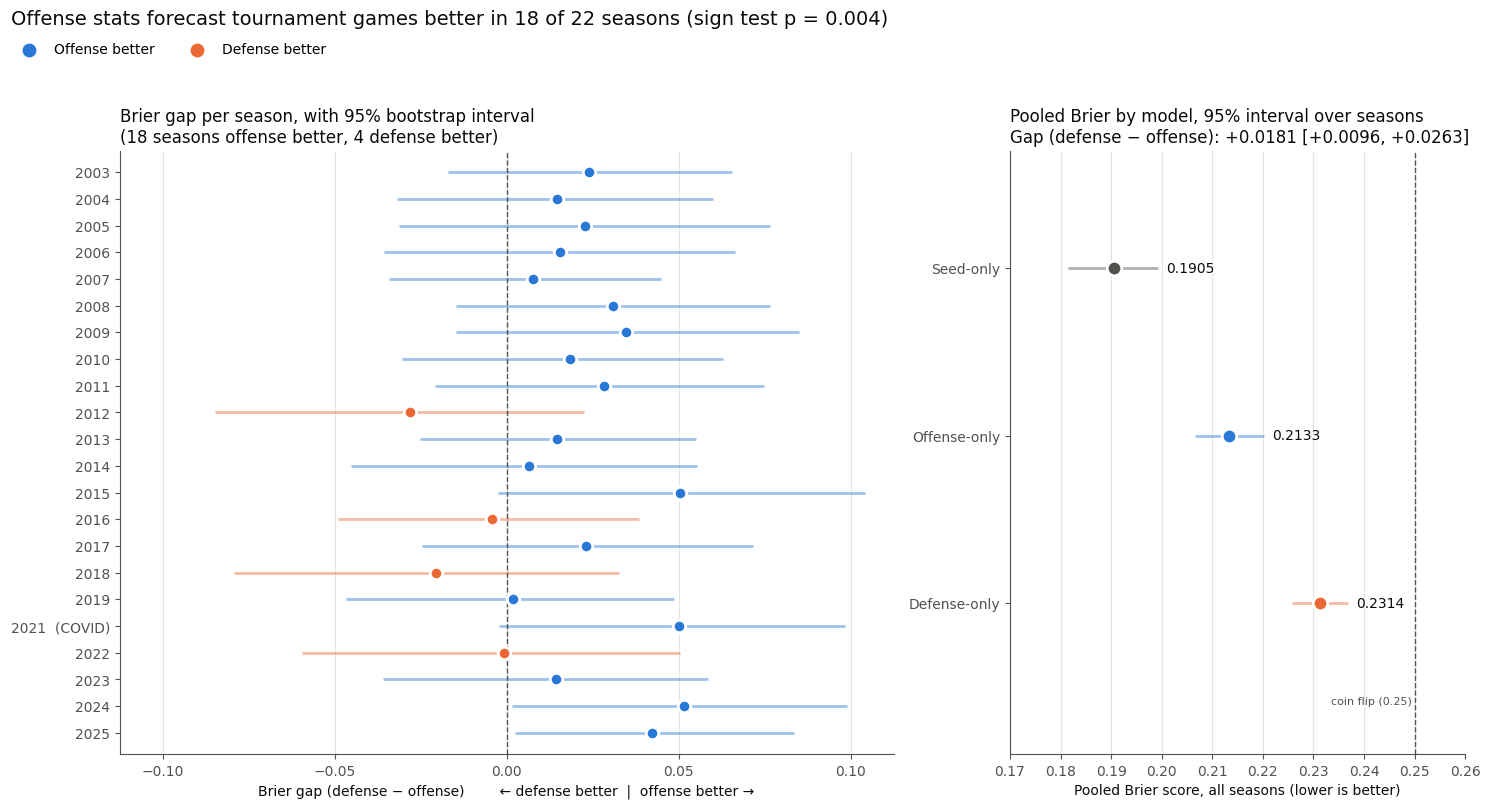

 Season  games  brier_off  brier_def     gap      lo     hi  winner
   2003     63     0.2047     0.2287  0.0240 -0.0170 0.0656 offense
   2004     63     0.2079     0.2226  0.0148 -0.0319 0.0599 offense
   2005     63     0.2086     0.2312  0.0226 -0.0314 0.0764 offense
   2006     63     0.2164     0.2319  0.0155 -0.0357 0.0663 offense
   2007     63     0.2013     0.2089  0.0076 -0.0342 0.0448 offense
   2008     63     0.1921     0.2231  0.0310 -0.0149 0.0765 offense
   2009     63     0.2009     0.2354  0.0346 -0.0148 0.0851 offense
   2010     63     0.2214     0.2398  0.0184 -0.0303 0.0630 offense
   2011     63     0.2217     0.2501  0.0283 -0.0209 0.0748 offense
   2012     63     0.2330     0.2048 -0.0282 -0.0848 0.0225 defense
   2013     63     0.2138     0.2284  0.0146 -0.0253 0.0549 offense
   2014     63     0.2185     0.2249  0.0064 -0.0454 0.0555 offense
   2015     63     0.1789     0.2294  0.0504 -0.0026 0.1042 offense
   2016     63     0.2255     0.2213 -0.0043 -0.

In [19]:
#@title Results: Brier gap by season (offense vs defense) + pooled Brier by model
# Self-contained: needs only `matchups`, SEED_FEATURES, OFF_FEATURES, DEF_FEATURES
# from the feature cell. If your modeling cell already produced out-of-sample
# probabilities, put them in `oos` (columns Season, Label, p_seed, p_off, p_def)
# and skip the leave-one-season-out block.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest
from sklearn.linear_model import LogisticRegression

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#b5b3ad"
INK, MUTED = "#0b0b0b", "#52514e"
RNG = np.random.default_rng(2010)
N_BOOT = 2000

MODELS = {"seed": SEED_FEATURES, "off": OFF_FEATURES, "def": DEF_FEATURES}
MODEL_NAMES = {"seed": "Seed-only", "off": "Offense-only", "def": "Defense-only"}
MODEL_COLORS = {"seed": MUTED, "off": BLUE, "def": ORANGE}

# ---- 1. Leave-one-season-out predictions (every game predicted by a model that never saw its season) ----
oos = matchups[["Season", "Label"]].copy()
for key, feats in MODELS.items():
    oos["p_" + key] = np.nan
    for season in sorted(matchups.Season.unique()):
        train, test = matchups.Season != season, matchups.Season == season
        clf = LogisticRegression(max_iter=1000).fit(matchups.loc[train, feats], matchups.loc[train, "Label"])
        oos.loc[test, "p_" + key] = clf.predict_proba(matchups.loc[test, feats])[:, 1]

for key in MODELS:                                   # squared error per game; Brier = its mean
    oos["se_" + key] = (oos["p_" + key] - oos.Label) ** 2
oos["gap"] = oos.se_def - oos.se_off                 # > 0 means offense forecast better

# ---- 2. Per-season gap with a bootstrap interval (resample games within the season) ----
rows = []
for season, g in oos.groupby("Season"):
    d = g.gap.to_numpy()
    boots = RNG.choice(d, size=(N_BOOT, len(d)), replace=True).mean(axis=1)
    lo, hi = np.percentile(boots, [2.5, 97.5])
    rows.append({"Season": season, "games": len(d), "brier_off": g.se_off.mean(),
                 "brier_def": g.se_def.mean(), "gap": d.mean(), "lo": lo, "hi": hi})
by_season = pd.DataFrame(rows)

off_wins = int((by_season.gap > 0).sum())
def_wins = int((by_season.gap < 0).sum())
sign_p = binomtest(off_wins, off_wins + def_wins, 0.5).pvalue

# ---- 3. Pooled Brier per model, bootstrap over whole seasons (keeps each season's games together) ----
seasons = by_season.Season.to_numpy()
season_sums = oos.groupby("Season")[["se_seed", "se_off", "se_def", "gap"]].sum().loc[seasons]
season_n = oos.groupby("Season").size().loc[seasons].to_numpy()
idx = RNG.integers(0, len(seasons), size=(N_BOOT, len(seasons)))
boot_pooled = {c: season_sums[c].to_numpy()[idx].sum(axis=1) / season_n[idx].sum(axis=1)
               for c in season_sums.columns}
pooled = pd.DataFrame({
    "model": [MODEL_NAMES[k] for k in MODELS],
    "brier": [oos["se_" + k].mean() for k in MODELS],
    "lo": [np.percentile(boot_pooled["se_" + k], 2.5) for k in MODELS],
    "hi": [np.percentile(boot_pooled["se_" + k], 97.5) for k in MODELS],
}, index=list(MODELS))
pooled_gap = oos.gap.mean()
pooled_gap_lo, pooled_gap_hi = np.percentile(boot_pooled["gap"], [2.5, 97.5])

# ---- 4. Figure ----
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 8.2), gridspec_kw={"width_ratios": [1.7, 1]})
fig.suptitle(f"Offense stats forecast tournament games better in {off_wins} of {off_wins + def_wins} seasons "
             f"(sign test p = {sign_p:.3f})", fontsize=14, x=0.01, ha="left", color=INK)

# Left: one row per season, newest at the bottom
y = np.arange(len(by_season))[::-1]
for yy, r in zip(y, by_season.itertuples()):
    color = BLUE if r.gap > 0 else ORANGE
    ax1.hlines(yy, r.lo, r.hi, color=color, linewidth=2, alpha=0.45)
    ax1.scatter(r.gap, yy, s=80, color=color, edgecolor="white", linewidth=2, zorder=3)
ax1.axvline(0, color=MUTED, linewidth=1, linestyle="--")
ax1.set_yticks(y, [f"{s}{'  (COVID)' if s == 2021 else ''}" for s in by_season.Season])
span = max(abs(by_season.lo.min()), abs(by_season.hi.max())) * 1.08
ax1.set_xlim(-span, span)
ax1.set_ylim(-0.8, len(by_season) - 0.2)
ax1.set_xlabel("Brier gap (defense − offense)        ← defense better  |  offense better →")
ax1.set_title(f"Brier gap per season, with 95% bootstrap interval\n"
              f"({off_wins} seasons offense better, {def_wins} defense better)", loc="left", color=INK)
ax1.grid(axis="y", visible=False)
ax1.scatter([], [], s=80, color=BLUE, label="Offense better")
ax1.scatter([], [], s=80, color=ORANGE, label="Defense better")
fig.legend(frameon=False, loc="upper left", bbox_to_anchor=(0.005, 0.955), ncol=2)

# Right: pooled Brier per model (dots, not bars: the differences live far from zero)
y2 = np.arange(len(pooled))[::-1]
for yy, (key, r) in zip(y2, pooled.iterrows()):
    ax2.hlines(yy, r.lo, r.hi, color=MODEL_COLORS[key], linewidth=2, alpha=0.45)
    ax2.scatter(r.brier, yy, s=110, color=MODEL_COLORS[key], edgecolor="white", linewidth=2, zorder=3)
    ax2.text(r.hi + 0.0015, yy, f"{r.brier:.4f}", va="center", ha="left", fontsize=10, color=INK)
ax2.axvline(0.25, color=MUTED, linewidth=1, linestyle="--")
ax2.text(0.2495, -0.6, "coin flip (0.25)", fontsize=8, color=MUTED, ha="right")
ax2.set_yticks(y2, pooled.model)
ax2.set_xlim(min(pooled.lo.min() - 0.006, 0.17), 0.26)
ax2.set_ylim(-0.9, len(pooled) - 0.3)
ax2.set_xlabel("Pooled Brier score, all seasons (lower is better)")
ax2.set_title(f"Pooled Brier by model, 95% interval over seasons\n"
              f"Gap (defense − offense): {pooled_gap:+.4f} [{pooled_gap_lo:+.4f}, {pooled_gap_hi:+.4f}]",
              loc="left", color=INK)
ax2.grid(axis="y", visible=False)

fig.tight_layout(rect=(0, 0, 1, 0.92))
fig.savefig("results_brier_gap.png", dpi=200, bbox_inches="tight")   # for the slide
plt.show()

# ---- 5. Table view of the same numbers ----
print(by_season.assign(winner=np.where(by_season.gap > 0, "offense", "defense"))
      .round({"brier_off": 4, "brier_def": 4, "gap": 4, "lo": 4, "hi": 4}).to_string(index=False))
print()
print(pooled.round(4).to_string(index=False))
print(f"\nPooled gap (defense − offense): {pooled_gap:+.4f}, 95% interval [{pooled_gap_lo:+.4f}, {pooled_gap_hi:+.4f}]")
print(f"Sign test: offense better in {off_wins}/{off_wins + def_wins} seasons, p = {sign_p:.4f}")